In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re
import nltk
from nltk.corpus import stopwords
from collections import Counter
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD

# Data Analysis and Preprocessing

In [2]:
df = pd.read_csv("/home/jovyan/work/data/IMDB Dataset.csv")

In [3]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
df.shape

(50000, 2)

In [5]:
df.columns

Index(['review', 'sentiment'], dtype='str')

In [6]:
df.dtypes

review       str
sentiment    str
dtype: object

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 63.6 MB


In [8]:
df.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [9]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(418)

In [11]:
df = df.dropna()
df = df.drop_duplicates()

In [12]:
df.shape

(49582, 2)

There are no missing values, so removing missing rows does not change the dataset. The 418 exact duplicate rows were removed so repeated reviews do not have extra influence on the analysis or models.

In [13]:
df.loc[df["sentiment"] == "positive", ["review", "sentiment"]].head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
5,"Probably my all-time favorite movie, a story o...",positive


In [14]:
df.iloc[np.r_[0:3, -3:]]

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive


In [15]:
df["sentiment"] = df["sentiment"].astype("category")

In [16]:
df["sentiment_encoded"] = (df["sentiment"] == "positive").astype(int)

In [17]:
def count_unique_words(review):
    return len(set(review.lower().split()))

df["char_count"] = df["review"].str.len()
df["word_count"] = df["review"].str.split().str.len()
df["unique_word_count"] = df["review"].map(count_unique_words)
df["avg_word_length"] = df["review"].str.replace(" ", "").str.len() / df["word_count"]

In [18]:
df["cluster"] = np.arange(len(df)) // 1000

In [19]:
original_distribution = df["sentiment"].value_counts(normalize=True)
original_distribution

sentiment
positive    0.501876
negative    0.498124
Name: proportion, dtype: float64

In [20]:
random_sample = df.sample(n=1000, random_state=42)

stratified_sample = df.groupby("sentiment", group_keys=False).sample(n=500, random_state=42)

selected_cluster = df["cluster"].drop_duplicates().sample(n=1, random_state=42).iloc[0]
cluster_sample = df[df["cluster"] == selected_cluster]
selected_cluster

np.int64(13)

In [21]:
pd.concat([
    original_distribution.rename("original"),
    random_sample["sentiment"].value_counts(normalize=True).rename("simple_random"),
    stratified_sample["sentiment"].value_counts(normalize=True).rename("stratified"),
    cluster_sample["sentiment"].value_counts(normalize=True).rename("cluster")
], axis=1).fillna(0)

,original,simple_random,stratified,cluster
sentiment,,,,
positive,0.501876,0.518,0.5,0.481
negative,0.498124,0.482,0.5,0.519


Simple random sampling gives every review the same chance of selection. Stratified sampling takes the same label proportion from each sentiment group. For cluster sampling, the dataset is divided into fixed 1,000-row clusters and one entire cluster is selected.

In [22]:
correlation_columns = ["char_count", "word_count", "unique_word_count", "avg_word_length", "sentiment_encoded"]
correlation = df[correlation_columns].corr()
correlation

,char_count,word_count,unique_word_count,avg_word_length,sentiment_encoded
char_count,1.000000,0.996844,0.990314,0.173673,0.015917
word_count,0.996844,1.000000,0.987082,0.111498,0.010184
unique_word_count,0.990314,0.987082,1.000000,0.169495,0.000143
avg_word_length,0.173673,0.111498,0.169495,1.000000,0.051240
sentiment_encoded,0.015917,0.010184,0.000143,0.051240,1.000000


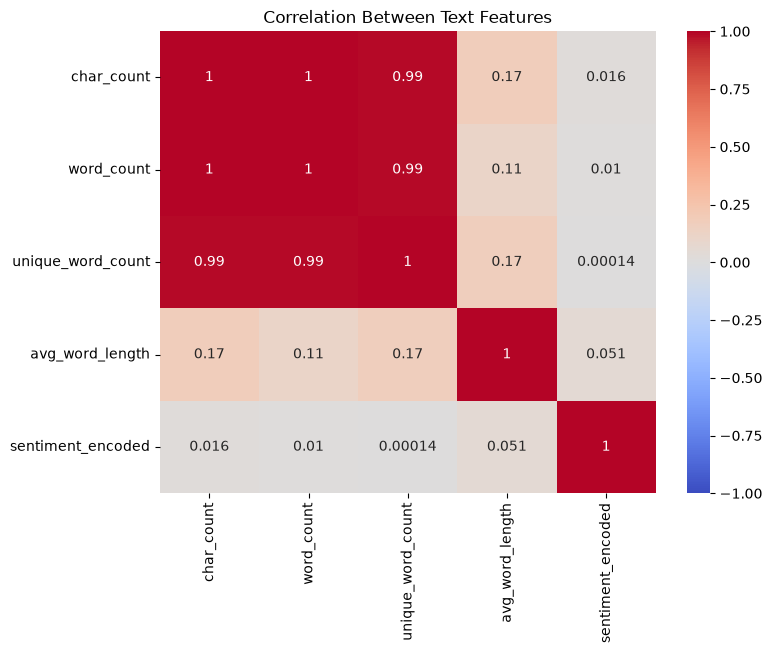

In [23]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Text Features")
plt.savefig("/home/jovyan/work/output/figures/correlation_heatmap.png", bbox_inches="tight")
plt.show()

taking avg word length as an example, it has highest correlation with sentiment, but that doesn't mean that avg word length causes a sentiment to be positive. It only means that in positive sentiment reviews, the avg word length tends to be higher. 

# Text Analysis 

In [24]:
def clean_text(text):
    if pd.isna(text):
        return ""
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", "", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"[^\w\s]", " ", text)
    return " ".join(text.split())

In [25]:
df["cleaned_text"] = df["review"].map(clean_text)

In [26]:
df[["review", "cleaned_text"]].head()

,review,cleaned_text
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...


In [27]:
token_counts = df["cleaned_text"].str.split().str.len()
total_tokens = token_counts.sum()
unique_words = len(set(" ".join(df["cleaned_text"]).split()))
average_words_per_record = token_counts.mean()

pd.Series({
    "total_tokens": total_tokens,
    "unique_words": unique_words,
    "average_words_per_record": average_words_per_record
})

total_tokens                1.161656e+07
unique_words                1.000100e+05
average_words_per_record    2.342898e+02
dtype: float64

In [28]:
nltk.download("stopwords")
stop_words = set(stopwords.words("english"))

[nltk_data] Downloading package stopwords to /home/jovyan/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [29]:
word_counts = Counter(" ".join(df["cleaned_text"]).split())
top_words_before = pd.DataFrame(word_counts.most_common(20), columns=["word", "count"])
top_words_before

,word,count
0,the,662907
1,and,322086
2,a,320733
3,of,287338
4,to,266118
5,is,209630
6,it,189437
7,in,185415
8,i,174122
9,this,149809


In [30]:
word_counts_after = Counter({word: count for word, count in word_counts.items() if word not in stop_words})
top_words_after = pd.DataFrame(word_counts_after.most_common(20), columns=["word", "count"])
top_words_after

,word,count
0,movie,87274
1,film,79147
2,one,53205
3,like,39843
4,good,29547
5,time,24904
6,even,24669
7,would,24401
8,story,22971
9,really,22923


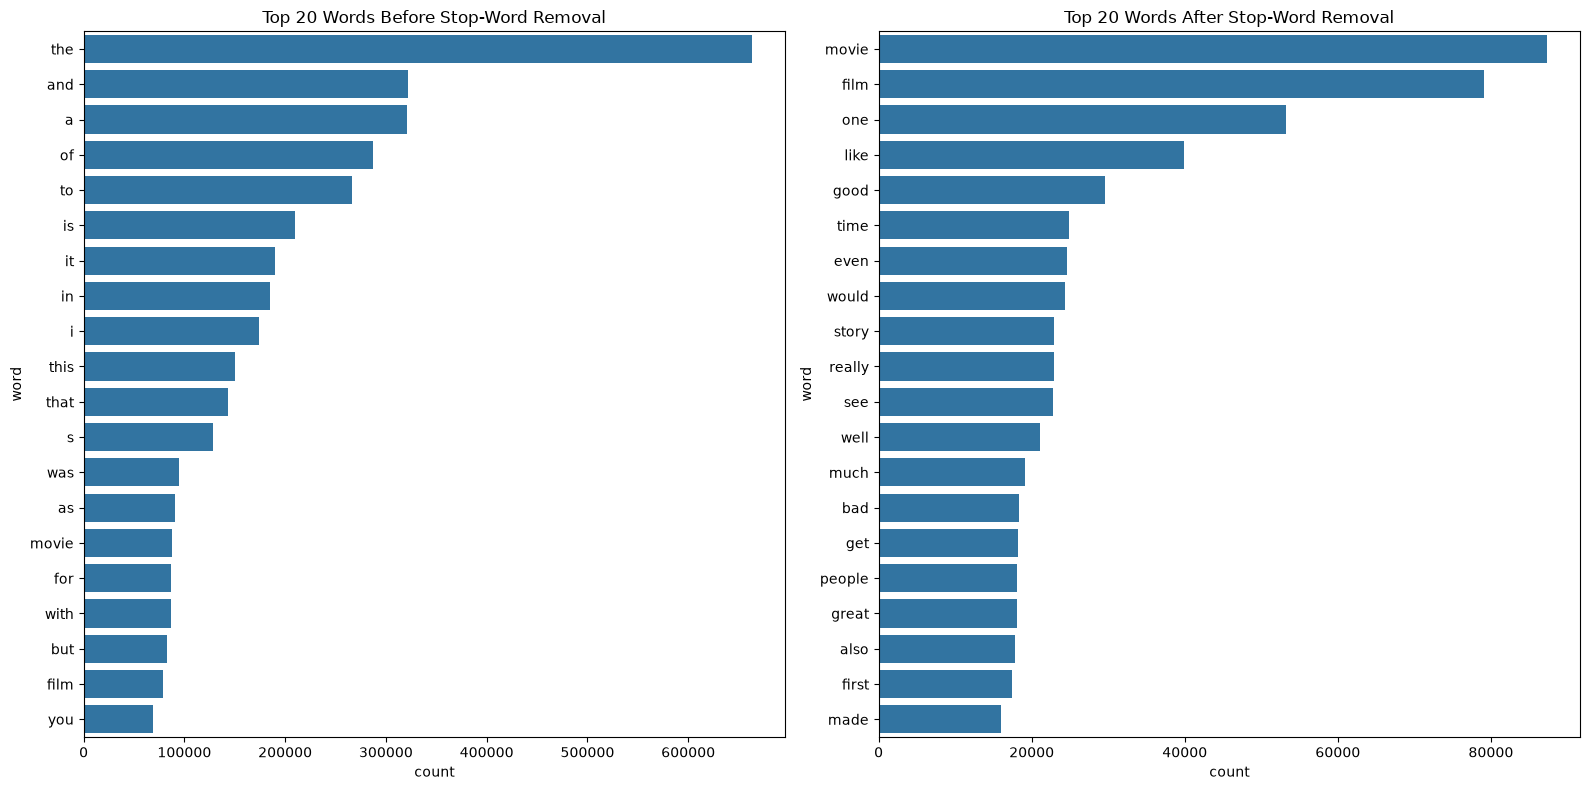

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
sns.barplot(data=top_words_before, x="count", y="word", ax=axes[0])
axes[0].set_title("Top 20 Words Before Stop-Word Removal")
sns.barplot(data=top_words_after, x="count", y="word", ax=axes[1])
axes[1].set_title("Top 20 Words After Stop-Word Removal")
plt.tight_layout()
plt.savefig("/home/jovyan/work/output/figures/word_frequency_comparison.png", bbox_inches="tight")
plt.show()

In [32]:
df["cleaned_char_count"] = df["cleaned_text"].str.len()
df["cleaned_word_count"] = df["cleaned_text"].str.split().str.len()

In [33]:
group_summary = df.groupby("sentiment", observed=False).agg(
    average_text_length=("cleaned_char_count", "mean"),
    average_word_count=("cleaned_word_count", "mean")
)
group_summary

,average_text_length,average_word_count
sentiment,,
negative,1232.515224,232.691271
positive,1266.072376,235.876427


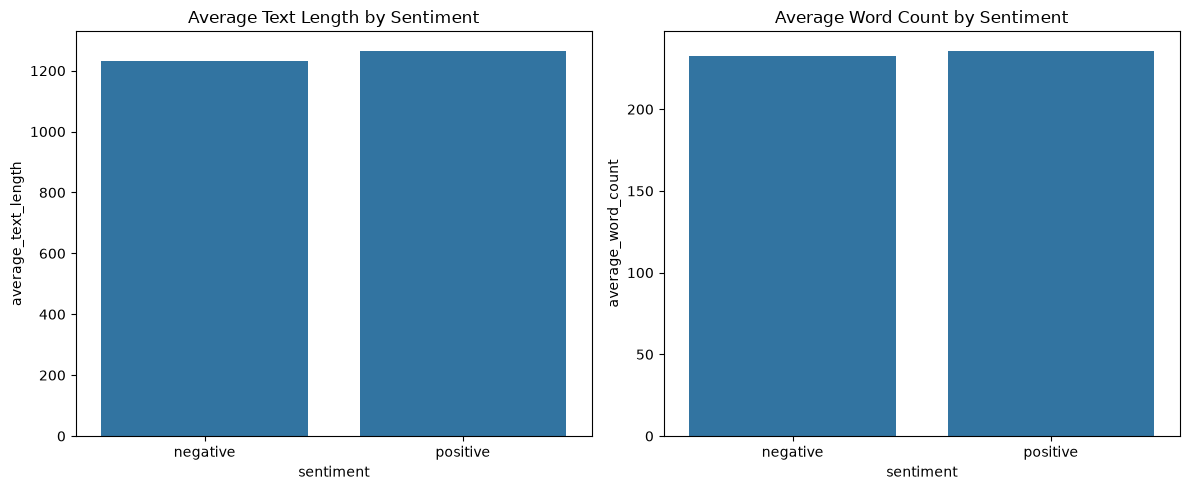

In [34]:
group_summary_plot = group_summary.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=group_summary_plot, x="sentiment", y="average_text_length", ax=axes[0])
axes[0].set_title("Average Text Length by Sentiment")
sns.barplot(data=group_summary_plot, x="sentiment", y="average_word_count", ax=axes[1])
axes[1].set_title("Average Word Count by Sentiment")
plt.tight_layout()
plt.savefig("/home/jovyan/work/output/figures/group_comparison.png", bbox_inches="tight")
plt.show()

In [35]:
def get_top_words(texts, n=10):
    counts = Counter()
    for text in texts:
        counts.update(word for word in text.split() if word not in stop_words)
    return counts.most_common(n)

In [36]:
positive_top_words = pd.DataFrame(
    get_top_words(df.loc[df["sentiment"] == "positive", "cleaned_text"]),
    columns=["positive_word", "positive_count"]
)
negative_top_words = pd.DataFrame(
    get_top_words(df.loc[df["sentiment"] == "negative", "cleaned_text"]),
    columns=["negative_word", "negative_count"]
)
pd.concat([positive_top_words, negative_top_words], axis=1)

,positive_word,positive_count,negative_word,negative_count
0,film,41968,movie,49615
1,movie,37659,film,37179
2,one,27210,one,25995
3,like,17651,like,22192
4,good,14966,even,15095
5,story,12898,good,14581
6,great,12889,bad,14563
7,time,12700,would,13854
8,well,12683,really,12217
9,see,12225,time,12204


In [37]:
# insight 1: good is in both positive words and negative words as seen in table above. Could be a problem with dataset or people like to say "not good"
# insight 2: People usually associate film with positive and movie with negative, as seen by top 2 in both word count.
# insight 3: The data contains lots of stop words as top 20 changed significantly before and after removal.
# insight 4: Data contains around 11 million tokens
# insight 5: Average review is around 233 words,  with positive reviews being longer than negative on average

In [38]:
df.head(1)

,review,sentiment,sentiment_encoded,char_count,word_count,unique_word_count,avg_word_length,cluster,cleaned_text,cleaned_char_count,cleaned_word_count
0,One of the other reviewers has mentioned that ...,positive,1,1761,307,200,4.739414,0,one of the other reviewers has mentioned that ...,1676,313


In [39]:
df[['cleaned_text', 'sentiment']].to_csv("/home/jovyan/work/output/files/cleaned_data.csv", index=False)

# Machine Learning

### Supervised Text Classification

In [40]:
X = df["cleaned_text"]
y = df["sentiment"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [41]:
tfidf = TfidfVectorizer(max_features=10000, stop_words="english")
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [42]:
logistic_reg = LogisticRegression()
logistic_reg.fit(X_train_tfidf, y_train)
y_pred_logistic = logistic_reg.predict(X_test_tfidf)

In [43]:
y_pred_train_logistic = logistic_reg.predict(X_train_tfidf)
print(accuracy_score(y_train, y_pred_train_logistic))

0.922450523131224


0.8902894020369063
              precision    recall  f1-score   support

    negative       0.90      0.87      0.89      4939
    positive       0.88      0.91      0.89      4978

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



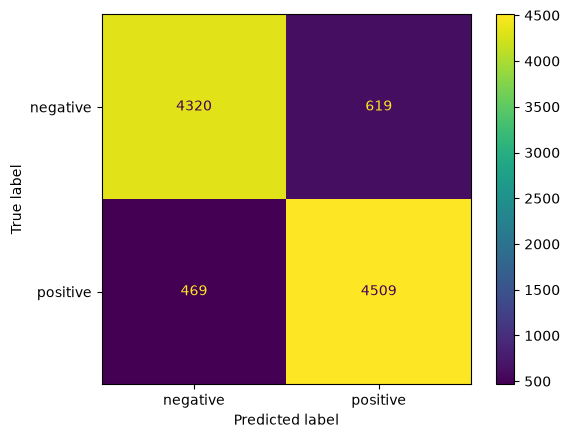

In [44]:
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_report = classification_report(y_test, y_pred_logistic)

with open(f"/home/jovyan/work/output/files/logisticReg_metrics.txt", "w") as file:
    file.write(f"Logistic Regression Accuracy: {logistic_accuracy:.4f}\n\n")
    file.write("Classification Report:\n")
    file.write(logistic_report)
    
print(logistic_accuracy)
print(logistic_report)

logistic_cm = confusion_matrix(y_test, y_pred_logistic, labels=logistic_reg.classes_)
logistic_disp = ConfusionMatrixDisplay(confusion_matrix=logistic_cm, display_labels=logistic_reg.classes_)

logistic_disp.plot()
plt.savefig("/home/jovyan/work/output/figures/logisticReg_confusion_matrix.png", bbox_inches="tight")
plt.show()

In [45]:
linearSVC = LinearSVC()
linearSVC.fit(X_train_tfidf, y_train)

y_pred_linearSVC = linearSVC.predict(X_test_tfidf)

In [46]:
y_pred_train_linearSVC = linearSVC.predict(X_train_tfidf)
print(accuracy_score(y_train, y_pred_train_linearSVC))

0.957040211773604


0.8815165876777251
              precision    recall  f1-score   support

    negative       0.89      0.87      0.88      4939
    positive       0.87      0.89      0.88      4978

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917



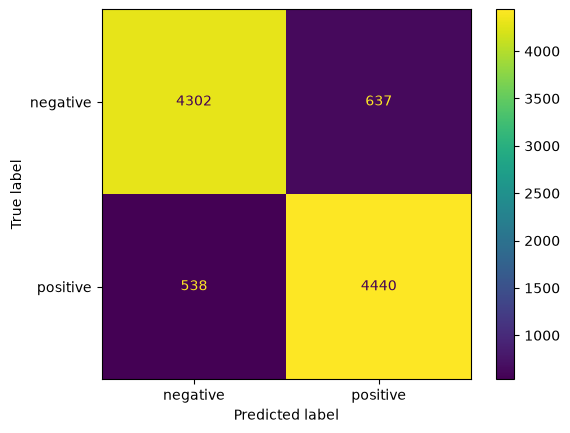

In [47]:
linearSVC_accuracy = accuracy_score(y_test, y_pred_linearSVC)
linearSVC_report = classification_report(y_test, y_pred_linearSVC)

with open(f"/home/jovyan/work/output/files/linearSVC_metrics.txt", "w") as file:
    file.write(f"LinearSVC Accuracy: {linearSVC_accuracy:.4f}\n\n")
    file.write("Classification Report:\n")
    file.write(linearSVC_report)
    
print(linearSVC_accuracy)
print(linearSVC_report)

linearSVC_cm = confusion_matrix(y_test, y_pred_linearSVC, labels=linearSVC.classes_)
linearSVC_disp = ConfusionMatrixDisplay(confusion_matrix=linearSVC_cm, display_labels=linearSVC.classes_)

linearSVC_disp.plot()
plt.savefig("/home/jovyan/work/output/figures/linearSVC_confusion_matrix.png", bbox_inches="tight")
plt.show()

The accuracy of the Logistic Regression model is a little bit higher than the LinearSVC's.  
The LinearSVC falls to significantly more false negatives compared to Logistic Regression.  
Limitation: LinearSVC overfits heavily on the data. Having approximately a 95% accuracy on train and 88% on test.

### K-Means Clustering

In [48]:
tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X_tfidf = tfidf.fit_transform(df["cleaned_text"])

In [49]:
svd = TruncatedSVD(n_components=100, random_state=42)
X_reduced = svd.fit_transform(X_tfidf)

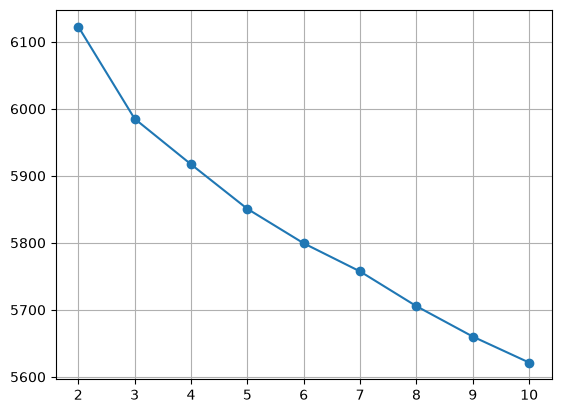

In [50]:
inertias = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_reduced)

    inertias.append(kmeans.inertia_)

plt.plot(range(2, 11), inertias, marker='o')
plt.grid(True)
plt.show()

In [51]:
for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_reduced)

    score = silhouette_score(
        X_reduced, labels,
        sample_size=3000,
        random_state=42
    )

    print(f"K={k}, Silhouette={score:.4f}")

K=2, Silhouette=0.0657
K=3, Silhouette=0.0302
K=4, Silhouette=0.0269
K=5, Silhouette=0.0254
K=6, Silhouette=0.0164
K=7, Silhouette=0.0158


In [52]:
kmeans = KMeans(n_clusters=4, random_state=42)
df["cluster"] = kmeans.fit_predict(X_reduced)

In [53]:
df["cluster"].value_counts()

cluster
2    22019
1     9996
0     9184
3     8383
Name: count, dtype: int64

In [54]:
crosstab = pd.crosstab(df["cluster"], df["sentiment"], margins=True)
crosstab

sentiment,negative,positive,All
cluster,,,
0,4684,4500,9184
1,4355,5641,9996
2,8517,13502,22019
3,7142,1241,8383
All,24698,24884,49582


In [55]:
quality_score = silhouette_score(X_reduced, df["cluster"])
quality_score

0.024265691795990803

In [56]:
terms = tfidf.get_feature_names_out()
centroids = svd.inverse_transform(kmeans.cluster_centers_)

for i, center in enumerate(centroids):
    top_words = sorted(zip(center, terms), reverse=True)[:30]
    print(f"Cluster {i}:", [word for score, word in top_words])

Cluster 0: ['movie', 'good', 'movies', 'like', 'just', 'really', 'great', 'watch', 'time', 'story', 'don', 'think', 'people', 'seen', 'did', 'love', 'make', 'acting', 'watching', 'film', 'bad', 'funny', 'know', 'plot', 'better', 'saw', 'way', 'say', 'characters', 'best']
Cluster 1: ['film', 'films', 'like', 'good', 'just', 'story', 'movie', 'time', 'great', 'really', 'people', 'characters', 'seen', 'character', 'make', 'way', 'think', 'plot', 'best', 'don', 'acting', 'watch', 'life', 'director', 'love', 'scenes', 'does', 'little', 'scene', 'end']
Cluster 2: ['movie', 'film', 'like', 'story', 'time', 'good', 'great', 'just', 'love', 'life', 'series', 'man', 'best', 'really', 'people', 'character', 'little', 'characters', 'way', 'young', 'years', 'cast', 'new', 'old', 'don', 'does', 'make', 'world', 'comedy', 'watch']
Cluster 3: ['bad', 'movie', 'just', 'like', 'really', 'good', 'film', 'don', 'movies', 'acting', 'time', 'plot', 'people', 'make', 'worst', 'seen', 'watch', 'think', 'thing

In [57]:
interpretations = """ 0: Mixed reviews
 1: More negative
 2: positive reviews related to different genres and types of films
 3: positive reviews but could be more related to a franchise. (film, films, director)
"""

In [58]:
with open(f"/home/jovyan/work/output/files/cluster_summary.txt", "w") as file:
    file.write("Clustering Info:\n")
    file.write(crosstab.to_string())
    file.write(f"\n\nSilhouette Score: {quality_score:.4f}\n\n")
    file.write("Interpretations:\n")
    file.write(interpretations)